<h3 style="font-weight:600;color:gold;">Pie with Labels</h3>

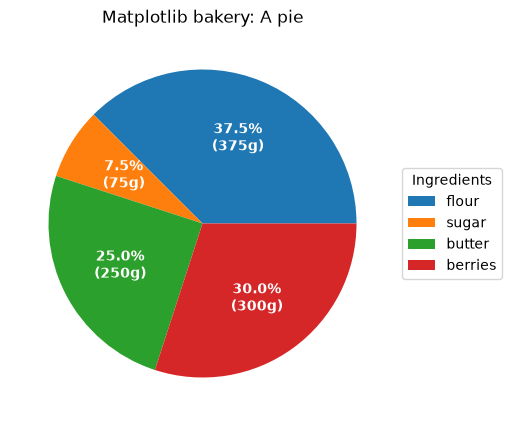

In [2]:
# Define the imports
import matplotlib.pyplot as plt
import numpy as np

# Create a figure with subplots
fig, ax = plt.subplots(figsize=(8, 5))

recipe = [
    "375 g flour",
    "75 g sugar",
    "250 g butter",
    "300 g berries",
]

# Isolate the numbers of grams - the data
data = [int(x.split()[0]) for x in recipe]
# Isolate the names of the ingredients - labels
ingredients = [x.split()[-1] for x in recipe]

# Get the PieContainer object
pie = ax.pie(data)

# Label each ingredient's wedge with percentages and its weight in grams
ax.pie_label(
    pie,  # container with all the wedges
    "{frac:.1%}\n({absval:d}g)",  # the labels for each wedge
    textprops=dict(
        color="w",
        size=10,
        weight="bold",
    ),
)
ax.legend(
    pie.wedges,  # use the pie's wedges, as the handles for the legend
    ingredients,  # use the ingredients as the labels for the legend
    title="Ingredients",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1),
)
ax.set_title("Matplotlib bakery: A pie")

plt.show()

<h3 style="font-weight:600;color:gold;">Donut with Labels</h3>

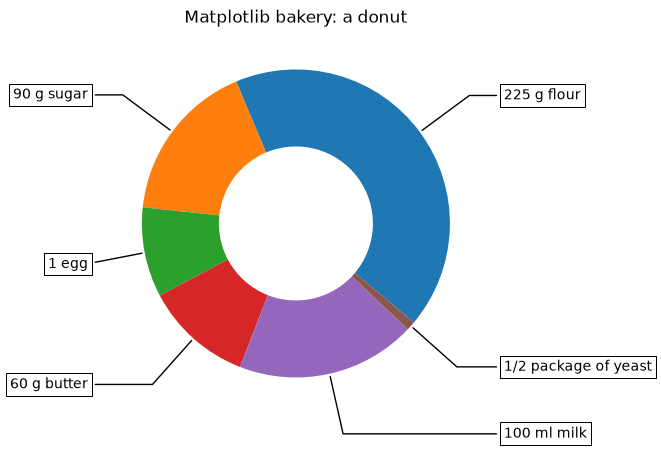

In [ ]:
# 1. Set up a square aspect coordinate system
fig, ax = plt.subplots(figsize=(8, 5), subplot_kw=dict(aspect="equal"))

recipe = [
    "225 g flour",
    "90 g sugar",
    "1 egg",
    "60 g butter",
    "100 ml milk",
    "1/2 package of yeast",
]

data = [225, 90, 50, 60, 100, 5]

# 2. Create a donut chart where the wedges have a hole in the middle. 
# This is achieved by setting the width of the wedges to 0.5 (instead of the default 1.0).
pie = ax.pie(data, wedgeprops=dict(width=0.5), startangle=-40)

bbox_props = dict(boxstyle="square,pad=0.3", fc="w", ec="k", lw=0.72)
kw = dict(
    arrowprops=dict(arrowstyle="-"),
    bbox=bbox_props,
    zorder=0,
    va="center",
)

# 3. For each wedge p calculate the exact center angle and use it for the label to point to.
for i, p in enumerate(pie.wedges):
    # Find the angle of the midpoint between the start and end angles of the wedge.
    ang = (p.theta2 - p.theta1) / 2.0 + p.theta1
    # Convert the polar to Cartesian coordinates.
    y = np.sin(np.deg2rad(ang))
    x = np.cos(np.deg2rad(ang))
    horizontalalignment = {-1: "right", 1: "left"}[int(np.sign(x))]
    connectionstyle = f"angle,angleA=0,angleB={ang}"
    kw["arrowprops"].update({"connectionstyle": connectionstyle})
    # 4. Place text boxes outside the chart, and draw lines connecting the boxes to the wedges.
    ax.annotate(
        recipe[i],
        xy=(x, y),
        xytext=(1.35 * np.sign(x), 1.4 * y),
        horizontalalignment=horizontalalignment,
        **kw,
    )

ax.set_title("Matplotlib bakery: a donut")
plt.show()